# CEMS — Community Participation Overview

**Question:** How does activity, RSVP follow-through,
and walk-in differ form other organizations

**Period:** January–October 2026

- Events hosted: Number of scheduled events.
- RSVP follow-through: Percentage of attending RSVPs with a recorded check-in.
- Walk-in share: Percentage of recorded check-ins without a matching RSVP.

In [2]:

from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from db_connector import get_connection


query_dir = Path("../sql/queries")

query_files = {
    "events": "02_events_by_organization.sql",
    "rsvp": "04_rsvp_check_in_follow_through.sql",
    "follow_through": "06_events_below_half_follow_through.sql",
    "walk_ins": "07_walk_in_attendance.sql",
}

results = {}

connection = get_connection()
cursor = connection.cursor(dictionary=True)

try:
    cursor.execute("SET SESSION time_zone = '+00:00'")

    for name, filename in query_files.items():
        sql = (query_dir / filename).read_text(encoding="utf-8")
        cursor.execute(sql)
        results[name] = pd.DataFrame(cursor.fetchall())

finally:
    cursor.close()
    connection.close()


# Combine the organization-level results.
summary = (
    results["events"]
    .merge(
        results["rsvp"][["organization", "check_in_rate_pct"]],
        on="organization"
    )
    .merge(
        results["walk_ins"],
        on="organization"
    )
    .sort_values("total_events", ascending=False)
    .reset_index(drop=True)
)

numeric_columns = [
    "total_events",
    "check_in_rate_pct",
    "total_check_ins",
    "walk_in_check_ins",
    "walk_in_pct",
]

for column in numeric_columns:
    summary[column] = pd.to_numeric(summary[column])

display(summary)


,organization,total_events,check_in_rate_pct,total_check_ins,walk_in_check_ins,walk_in_pct
0,Gaming Community,60,44.9,3039,424.0,14.0
1,Front Range Open Source & Technology Collective,43,83.2,2073,172.0,8.3
2,Ethical Non-Monogamy Community,42,76.5,1497,127.0,8.5
3,Rollerblading Community,34,76.7,1423,130.0,9.1
4,Pagan / Nontraditional Religion Community,30,78.2,1442,105.0,7.3


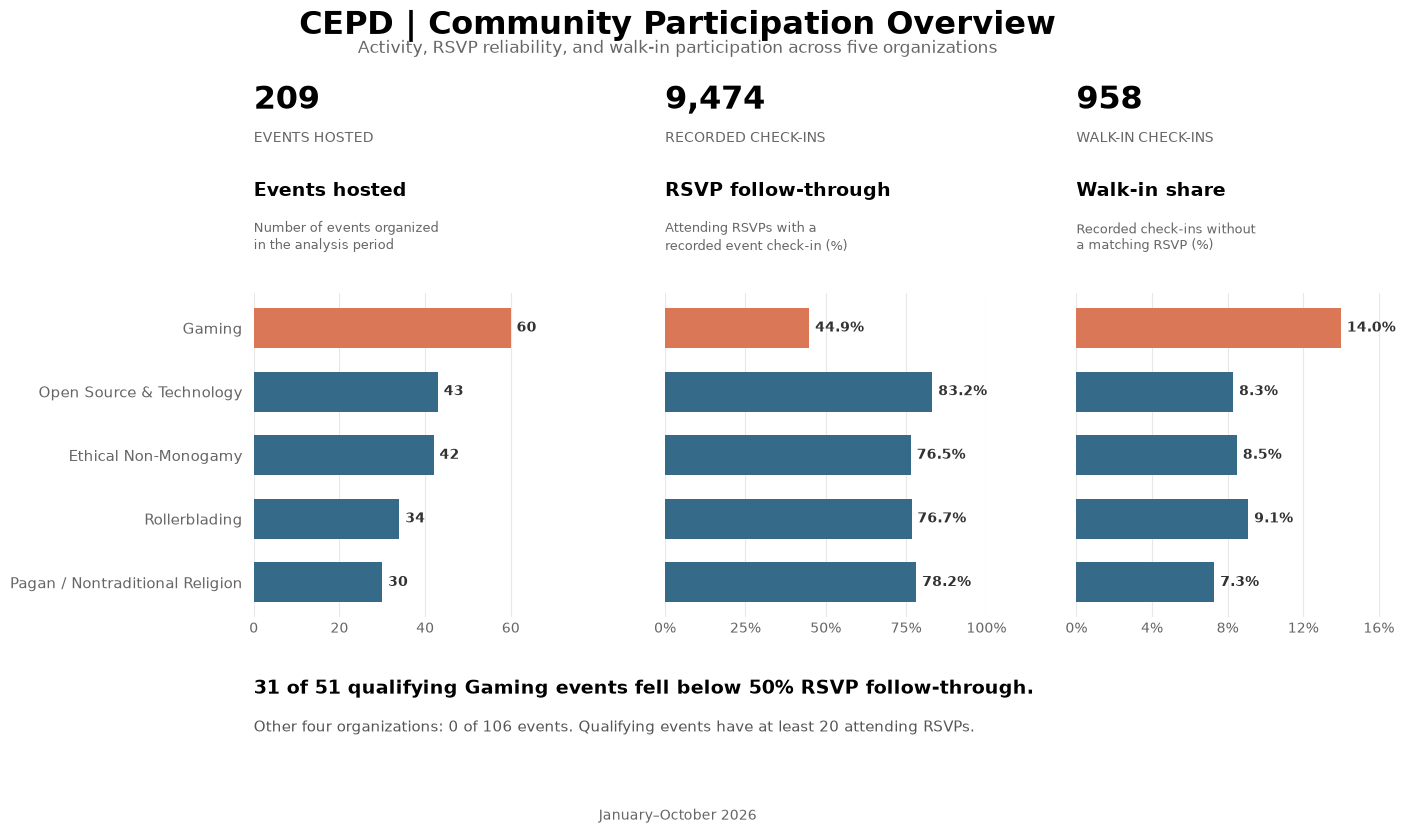

Saved visualization: output\community_overview.png


In [3]:

chart_data = summary.sort_values(
    "total_events", ascending=False
).copy()

short_names = {
    "Gaming Community": "Gaming",
    "Front Range Open Source & Technology Collective": "Open Source & Technology",
    "Ethical Non-Monogamy Community": "Ethical Non-Monogamy",
    "Rollerblading Community": "Rollerblading",
    "Pagan / Nontraditional Religion Community": "Pagan / Nontraditional Religion",
}

chart_data["label"] = chart_data["organization"].replace(short_names)

colors = [
    "#D97757" if name == "Gaming Community" else "#356B89"
    for name in chart_data["organization"]
]

# Calculate metrics 
total_events = int(chart_data["total_events"].sum())
total_check_ins = int(chart_data["total_check_ins"].sum())
total_walk_ins = int(chart_data["walk_in_check_ins"].sum())

# Query 6: Events with follow-through below 50%.
follow_through = results["follow_through"]

gaming = follow_through.loc[
    follow_through["organization"] == "Gaming Community"
].iloc[0]

others = follow_through.loc[
    follow_through["organization"] != "Gaming Community"
]

gaming_low = int(gaming["events_below_50_pct"])
gaming_total = int(gaming["qualifying_events"])

other_low = int(others["events_below_50_pct"].sum())
other_total = int(others["qualifying_events"].sum())


fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 9),
    sharey=True
)

fig.patch.set_facecolor("white")

fig.subplots_adjust(
    left=0.235,
    right=0.95,
    top=0.65,
    bottom=0.29,
    wspace=0.28
)

fig.suptitle(
    "CEPD | Community Participation Overview",
    fontsize=23,
    fontweight="bold",
    y=0.965
)

fig.text(
    0.5,
    0.917,
    "Activity, RSVP reliability, and walk-in participation across five organizations",
    ha="center",
    fontsize=12,
    color="#666666"
)

# Summary Metrics - Left Aligned 

metrics = [
    (total_events, "EVENTS HOSTED"),
    (total_check_ins, "RECORDED CHECK-INS"),
    (total_walk_ins, "WALK-IN CHECK-INS"),
]

for ax, (value, label) in zip(axes, metrics):
    left = ax.get_position().x0

    fig.text(
        left,
        0.855,
        f"{value:,}",
        ha="left",
        fontsize=23,
        fontweight="bold"
    )

    fig.text(
        left,
        0.818,
        label,
        ha="left",
        fontsize=10,
        color="#666666"
    )

# Panel Settings

panels = [
    {
        "column": "total_events",
        "title": "Events hosted",
        "definition": "Number of events organized\nin the analysis period",
        "limit": 75,
        "ticks": [0, 20, 40, 60],
        "percentage": False,
    },
    {
        "column": "check_in_rate_pct",
        "title": "RSVP follow-through",
        "definition": "Attending RSVPs with a\nrecorded event check-in (%)",
        "limit": 100,
        "ticks": [0, 25, 50, 75, 100],
        "percentage": True,
    },
    {
        "column": "walk_in_pct",
        "title": "Walk-in share",
        "definition": "Recorded check-ins without\na matching RSVP (%)",
        "limit": 17,
        "ticks": [0, 4, 8, 12, 16],
        "percentage": True,
    },
]


for ax, panel in zip(axes, panels):

    column = panel["column"]
    values = pd.to_numeric(chart_data[column])

    bars = ax.barh(
        range(len(chart_data)),
        values,
        color=colors,
        height=0.63
    )

    ax.set_xlim(0, panel["limit"])
    ax.set_xticks(panel["ticks"])

    if panel["percentage"]:
        ax.set_xticklabels(
            [f"{tick}%" for tick in panel["ticks"]]
        )

    ax.tick_params(
        axis="both",
        length=0,
        labelsize=10,
        colors="#666666"
    )

    ax.grid(
        axis="x",
        color="#E8E8E8",
        linewidth=0.8
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

    # Left-align each title and definition with its bars.
    left = ax.get_position().x0

    fig.text(
        left,
        0.758,
        panel["title"],
        ha="left",
        fontsize=14,
        fontweight="bold"
    )

    fig.text(
        left,
        0.713,
        panel["definition"],
        ha="left",
        va="center",
        fontsize=9.5,
        color="#666666",
        linespacing=1.3
    )

    # Position all values to the right of their bars.
    for bar, value in zip(bars, values):

        y = bar.get_y() + bar.get_height() / 2

        label_text = (
            f"{value:.1f}%"
            if panel["percentage"]
            else f"{int(value)}"
        )

        ax.text(
            value + panel["limit"] * 0.018,
            y,
            label_text,
            ha="left",
            va="center",
            color="#333333",
            fontsize=10,
            fontweight="bold"
        )

# Labels 

axes[0].set_yticks(
    range(len(chart_data)),
    chart_data["label"],
    fontsize=11
)

axes[0].invert_yaxis()
axes[0].tick_params(axis="y", pad=8)

for ax in axes[1:]:
    ax.tick_params(axis="y", labelleft=False)


# Core Findings - Left Aligned

fig.text(
    0.235,
    0.205,
    (
        f"{gaming_low} of {gaming_total} qualifying Gaming events "
        "fell below 50% RSVP follow-through."
    ),
    fontsize=14,
    fontweight="bold"
)

fig.text(
    0.235,
    0.163,
    (
        f"Other four organizations: {other_low} of {other_total} events. "
        "Qualifying events have at least 20 attending RSVPs."
    ),
    fontsize=10.5,
    color="#555555"
)


fig.text(
    0.5,
    0.065,
    (
        "January–October 2026"
    ),
    ha="center",
    fontsize=10,
    color="#666666"
)

# Export and display

output_path = Path("output/community_overview.png")
output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=200,
    facecolor="white"
)

plt.show()

print(f"Saved visualization: {output_path}")
